The goal is to predict whether an individual earns more than 50K per year.

Features:
age – Age of the individual
workclass – Type of employment (e.g., Private, Self-emp, Government, etc.)
fnlwgt – Final weight, used by the Census Bureau to estimate population statistics
education – Highest education level achieved
education.num – Numerical representation of education level
marital.status – Marital status
occupation – Occupation type
relationship – Relationship status within the household
race – Race of the individual
sex – Gender of the individual
capital.gain – Capital gains reported
capital.loss – Capital losses reported
hours.per.week – Hours worked per week
native.country – Country of origin
income – Income level (<=50K or >50K, classification target)

In [13]:
# Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
# Загрузка данных
df=pd.read_csv('data.csv')
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90.0,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82.0,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66.0,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54.0,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41.0,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [15]:
# Проверка на пропуски
df_clean = df.replace("?", np.nan)
df.isnull().sum()

,0
age,513
workclass,2103
fnlwgt,0
education,231
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


In [16]:
# Удаление пропусков или замена в категориальном признаке на моду
df_clean['workclass'] = df['workclass'].fillna(df['workclass'].mode()[0])
df_clean = df_clean.dropna()
df_clean.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


In [17]:
# Список категориальных признаков
df_clean.select_dtypes(include=['object']).columns

Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income'],
      dtype='object')

In [18]:
# Удаление столбца имеющего большую зависимость с другим (education.num)
df_clean = df_clean.drop(columns=['education'])

In [19]:
# Уникальные значение столбцов
df_clean['income'].unique()
df_clean['race'].unique()

array(['White', 'Black', 'Asian-Pac-Islander', 'Other',
       'Amer-Indian-Eskimo'], dtype=object)

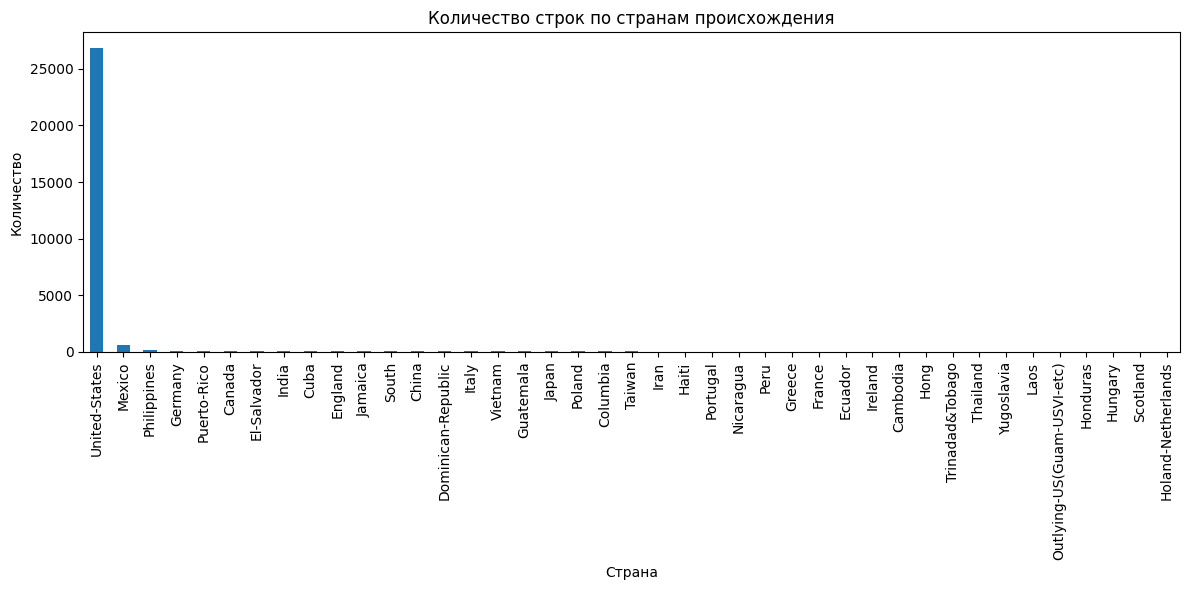

In [20]:
country_counts = df_clean['native.country'].value_counts()
plt.figure(figsize=(12, 6))
country_counts.plot(kind='bar')
plt.title('Количество строк по странам происхождения')
plt.xlabel('Страна')
plt.ylabel('Количество')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [21]:
# Кодирование категориальных столбцов, имеющий только два уникальных значения (для страны происхождения разделяем на живёт в US и не живёт)
from sklearn.preprocessing import LabelEncoder

lab_encoder = LabelEncoder()
df_clean["sex"] = lab_encoder.fit_transform(df_clean["sex"])
df_clean["income"]=lab_encoder.fit_transform(df_clean["income"])
df_clean['native.country'] = (df_clean['native.country'] == 'United-States').astype(int)
df_clean.head()

,age,workclass,fnlwgt,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
1,82.0,Private,132870,9,Widowed,Exec-managerial,Not-in-family,White,0,0,4356,18,1,0
3,54.0,Private,140359,4,Divorced,Machine-op-inspct,Unmarried,White,0,0,3900,40,1,0
4,41.0,Private,264663,10,Separated,Prof-specialty,Own-child,White,0,0,3900,40,1,0
5,34.0,Private,216864,9,Divorced,Other-service,Unmarried,White,0,0,3770,45,1,0
6,38.0,Private,150601,6,Separated,Adm-clerical,Unmarried,White,1,0,3770,40,1,0


In [22]:
!pip install category_encoders

In [23]:
# Остальные категориальные признаки обрабатываем с помощью OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

onehot = OneHotEncoder()
encode = onehot.fit_transform(df_clean[['race']])
df_encoded = pd.DataFrame(encode.toarray(), columns=onehot.categories_[0], index=df_clean.index)
df_clean = df_clean.join(df_encoded)
df_clean.drop('race', axis = 1, inplace = True)

onehot = OneHotEncoder()
encode = onehot.fit_transform(df_clean[['workclass']])
df_encoded = pd.DataFrame(encode.toarray(), columns=onehot.categories_[0], index=df_clean.index)
df_clean = df_clean.join(df_encoded)
df_clean.drop('workclass', axis = 1, inplace = True)

onehot = OneHotEncoder()
encode = onehot.fit_transform(df_clean[['marital.status']])
df_encoded = pd.DataFrame(encode.toarray(), columns=onehot.categories_[0], index=df_clean.index)
df_clean = df_clean.join(df_encoded)
df_clean.drop('marital.status', axis = 1, inplace = True)

onehot = OneHotEncoder()
encode = onehot.fit_transform(df_clean[['occupation']])
df_encoded = pd.DataFrame(encode.toarray(), columns=onehot.categories_[0], index=df_clean.index)
df_clean = df_clean.join(df_encoded)
df_clean.drop('occupation', axis = 1, inplace = True)

onehot = OneHotEncoder()
encode = onehot.fit_transform(df_clean[['relationship']])
df_encoded = pd.DataFrame(encode.toarray(), columns=onehot.categories_[0], index=df_clean.index)
df_clean = df_clean.join(df_encoded)
df_clean.drop('relationship', axis = 1, inplace = True)

<Axes: xlabel='capital.loss'>

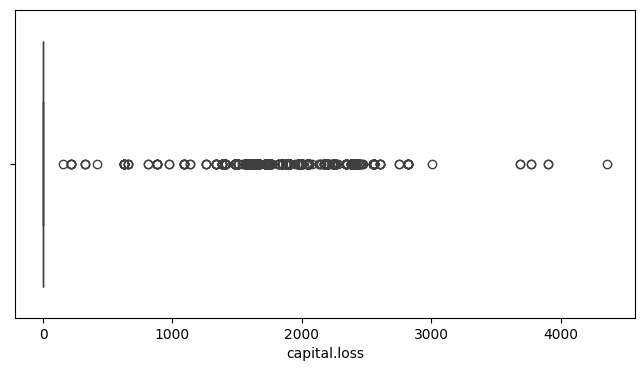

In [24]:
# Просмотр распределения значений столбцов capital.loss и capital.gain с помощью "ящика с усами"
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['capital.loss'])

<Axes: xlabel='capital.gain', ylabel='Count'>

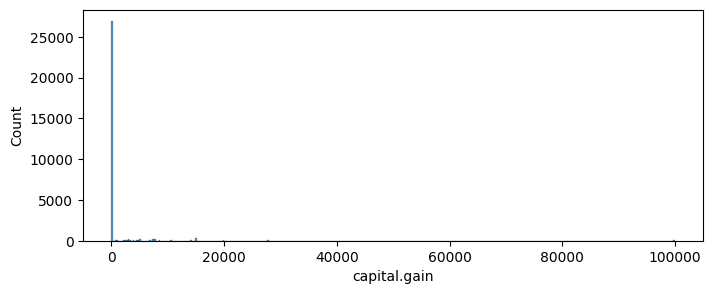

In [25]:
plt.figure(figsize=(8, 3))
sns.histplot(df_clean, x="capital.gain")

In [26]:
# Основная часть собрана в нуле, поэтому преобразуем признаки в has_loss и has_gain (аналогия с US)
df_clean['has_loss'] = (df_clean['capital.loss'] > 0).astype(int)
df_clean = df_clean.drop(columns=['capital.loss'])
df_clean['has_gain'] = (df_clean['capital.gain'] > 0).astype(int)
df_clean = df_clean.drop(columns=['capital.gain'])

In [27]:
# Удаляем ненужный признак и разделяем выборку на тренировочную и тестувую
from sklearn.model_selection import train_test_split
X = df_clean.drop(['income', 'fnlwgt'], axis=1)
y = df_clean['income']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)

In [28]:
# Обучаем логистическую регрессию с l2 регуляризацией и т к классы не сбалансированы (см след ячейку) применяем автоматическую компенсацию дисбаланса классов
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(penalty='l2', C=5.0, max_iter=200, solver='newton-cg', random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

LogisticRegression(C=5.0, class_weight='balanced', max_iter=200,
                   random_state=42, solver='newton-cg')

<Axes: xlabel='income', ylabel='Count'>

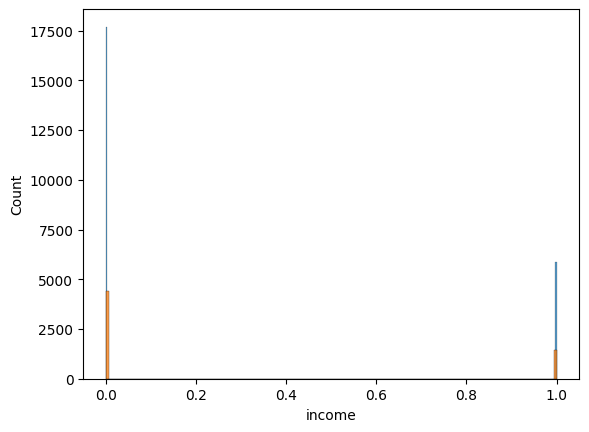

In [29]:
# Проверяем, как распределились значения
sns.histplot(y_train)
sns.histplot(y_test)

In [30]:
# Получаем предсказанные значения
y_pred = model.predict(X_test)

In [31]:
# Оценка качества обученной модели
from sklearn import metrics

print('Accuracy = ', metrics.accuracy_score(y_test, y_pred))
print('F1 = ', metrics.f1_score(y_test, y_pred))

Accuracy =  0.8006447234475738
F1 =  0.6760408050730632


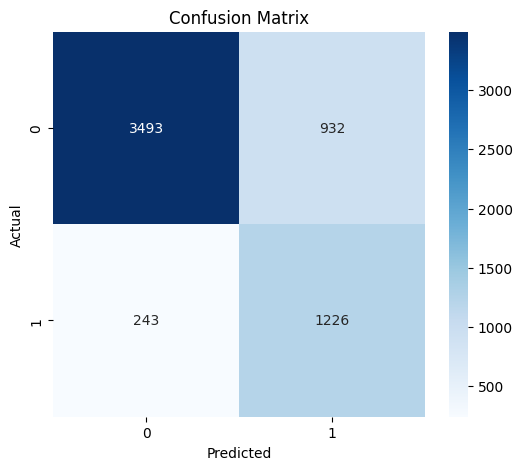

In [32]:
# Матрица ошибок
cm = metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

ROC-AUC =  0.8119799394645654


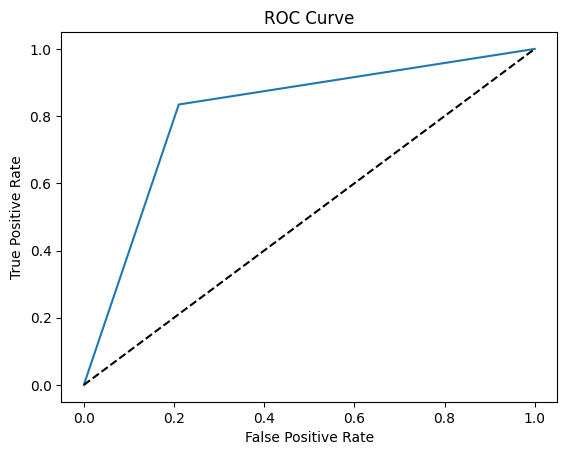

In [33]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

#вычисление ROC-AUC
auc_score = roc_auc_score(y_test, y_pred)
print('ROC-AUC = ', auc_score)

# Построение ROC-кривой
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [34]:
# Автоматический подбор порога по метрике f1
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(penalty='l2', C=5.0, max_iter=200, solver='newton-cg', random_state=42)

tuned = TunedThresholdClassifierCV(
    model,
    scoring="f1",
    cv=5
)

tuned.fit(X_train, y_train)
print("Подобранный порог:", tuned.best_threshold_)
y_pred = tuned.predict(X_test)

print('Accuracy = ', metrics.accuracy_score(y_test, y_pred))
print('F1 = ', metrics.f1_score(y_test, y_pred))

Подобранный порог: 0.331374180157816
Accuracy =  0.8210044112656939
F1 =  0.675284702985534
